In [9]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import (apply_plot_style, 
                         get_layers, 
                         load_ii_curves, 
                         linestyle_for_language, 
                         _min_token_length)
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()


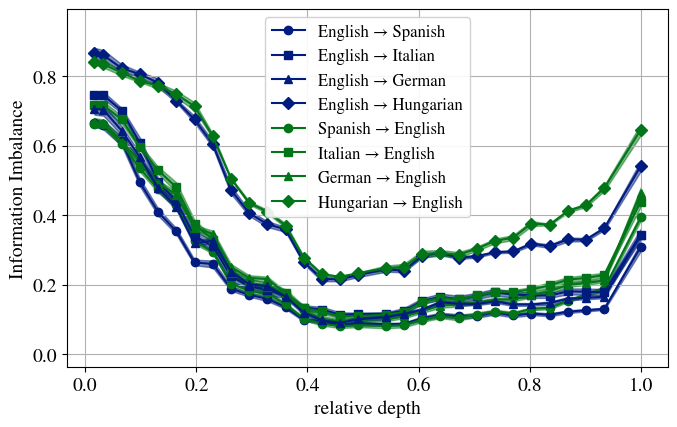

In [10]:
model = 'deepseek'
_model ='deepseek'

# model = "llama"
# _model = 'llama8b'

# MODEL_PRETTY = {"deepseek": "DeepSeek-V3", "llama": "Llama3-8b"}
# _model = MODEL_PRETTY.get(model, model)

mask = 2
n_files = 500
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0


aux_A = "source"
aux_B = "target"
k_II = 10
avg_tokens = 1
n_tokens = 20
Nbits = 0
seeds = list(range(5))
language_pairs = [
    ("english", "spanish"),
    ("english", "italian"),
    ("german", "english"),
    # ("english", "french"),
    # ("english", "dutch"),
    ("english", "hungarian"),
]

layers = get_layers(_model, depths)
x = layers / depths[_model]

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))

markers = ["o", "s", "^", "D", "v", "P", "X", "*", "+", "x"]

for i, (languageA, languageB) in enumerate(language_pairs):
    mean_ii, std_ii = load_ii_curves(
        base="../results/santiago/",
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=_min_token_length(model, languageA, languageB),
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits,
        seeds=seeds,
        n_tokens=n_tokens,
        avg_tokens=avg_tokens,
    )

    if languageA == "german" and languageB == "english":
        color_AB = colors[1]
        color_BA = colors[0]
    else:
        color_AB = colors[0]
        color_BA = colors[1]
    marker = markers[i % len(markers)]

    # AB
    ax.plot(
        x,
        mean_ii[0],
        label=f"{languageA.capitalize()} → {languageB.capitalize()}",
        linestyle='-',
        marker=marker,
        color=color_AB,
    )
    ax.fill_between(x, mean_ii[0] - std_ii[0], mean_ii[0] + std_ii[0], color=color_AB, alpha=0.5)

    # BA
    ax.plot(
        x,
        mean_ii[1],
        label=f"{languageB.capitalize()} → {languageA.capitalize()}",
        linestyle='-',
        marker=marker,
        color=color_BA,
    )
    ax.fill_between(x, mean_ii[1] - std_ii[1], mean_ii[1] + std_ii[1], color=color_BA, alpha=0.5)

ax.set_xlabel("relative depth")
ax.set_ylabel("Information Imbalance")
ax.grid()

# Legend inside plot
handles, labels = ax.get_legend_handles_labels()
english_to_other = [(h, l) for h, l in zip(handles, labels) if l.startswith("English →")]
other_to_english = [(h, l) for h, l in zip(handles, labels) if l.endswith("→ English")]
remaining = [
    (h, l)
    for h, l in zip(handles, labels)
    if not l.startswith("English →") and not l.endswith("→ English")
]
ordered = english_to_other + other_to_english + remaining
ordered_handles = [h for h, _ in ordered]
ordered_labels = [l for _, l in ordered]

ymin, ymax = ax.get_ylim()
pad = 0.08 * (ymax - ymin)
ax.set_ylim(ymin - pad, ymax + pad)

ax.legend(ordered_handles, ordered_labels, loc="upper center", fontsize=12, framealpha=0.9)
fig.savefig(f'../results/figs/english-pivot.pdf',bbox_inches='tight')
plt.show()

In [11]:
# avg_tokens_cases = [
#     (0, "Concat"),
#     (1, "Avg"),
# ]

# n_tokens_cases = [
#     (1, "Last token"),
#     (n_tokens, f"T={n_tokens}"),
# ]

# linestyles = ["-", "--"]

# fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))

# for token_case_id, (n_tokens_case, token_label) in enumerate(n_tokens_cases):
#     for case_id, (avg_tokens_case, case_label) in enumerate(avg_tokens_cases):
#         if n_tokens_case == 1 and avg_tokens_case == 1:
#             continue

#         asym_list = []
#         for (languageA, languageB) in language_pairs:
#             mean_ii, _ = load_ii_curves(
#                 base="../results/santiago/",
#                 batch_shuffle=batch_shuffle,
#                 model=model,
#                 aux_A=aux_A,
#                 aux_B=aux_B,
#                 n_files=n_files,
#                 min_token_length=_min_token_length(model, languageA, languageB),
#                 languageA=languageA,
#                 languageB=languageB,
#                 mask=mask,
#                 k=k_II,
#                 Nbits=Nbits,
#                 seeds=seeds,
#                 n_tokens=n_tokens_case,
#                 avg_tokens=avg_tokens_case,
#             )
#             a = mean_ii[0] - mean_ii[1]
#             a = -1 * a if languageA == "german" else a
#             asym_list.append(a)

#         asym = np.stack(asym_list, axis=0)
#         asym_mean = asym.mean(axis=0)
#         asym_std = asym.std(axis=0)

#         if n_tokens_case == 1:
#             color = colors[2 % len(colors)]
#         else:
#             color = colors[case_id % len(colors)]

#         if n_tokens_case == 1:
#             label = "Last token"
#         else:
#             label = f"{case_label} (avg_tokens={avg_tokens_case}, {token_label})"

#         ax.plot(
#             x,
#             asym_mean,
#             color=color,
#             label=label,
#         )
#         ax.fill_between(x, asym_mean - asym_std, asym_mean + asym_std, color=color, alpha=0.25)

# ax.axhline(0, color='black', linewidth=1, alpha=0.6)
# ax.set_xlabel("relative depth")
# ax.set_ylabel("II asymmetry (AB - BA)")
# ax.legend()
# # fig.savefig(fname=f'../results/figs/fig1_asym_avg_languages.pdf', bbox_inches='tight')
# plt.show()
